In [1]:
import urllib.request

url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(
    url,
    "sms_spam_collection.zip"
)

print("Dataset downloaded successfully!")

Dataset downloaded successfully!


In [2]:
import zipfile

with zipfile.ZipFile("sms_spam_collection.zip", "r") as zip_ref:
    zip_ref.extractall("sms_dataset")

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [3]:
import os

print(os.listdir("sms_dataset"))

['readme', 'SMSSpamCollection']


In [9]:



df = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())

First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape:
(5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64


First 5 rows:
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...

Dataset shape:
(5572, 2)

Class distribution:
label
ham     4825
spam     747
Name: count, dtype: int64

Converted labels:
  label                                            message  label_num
0   ham  Go until jurong point, crazy.. Available only ...          0
1   ham                      Ok lar... Joking wif u oni...          0
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...          1
3   ham  U dun say so early hor... U c already then say...          0
4   ham  Nah I don't think he goes to usf, he lives aro...          0

Training samples: 4457
Testing samples: 1115

Training feature shape: (4457, 7403)
Test

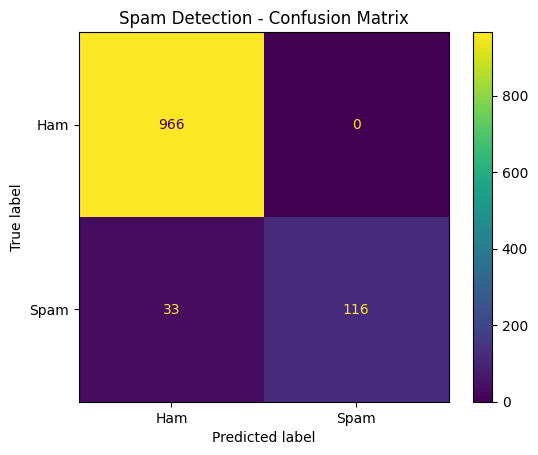


Message: Hey, are we meeting today?
Prediction: HAM

Message: Congratulations! You have won a free lottery prize!
Prediction: SPAM


In [11]:
# 1. Import libraries

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


# 2. Load the dataset

df = pd.read_csv(
    "sms_dataset/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print("First 5 rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\nClass distribution:")
print(df["label"].value_counts())


# 3. Convert labels into numbers

df["label_num"] = df["label"].map({
    "ham": 0,
    "spam": 1
})

print("\nConverted labels:")
print(df.head())


# 4. Separate features and target

X = df["message"]
y = df["label_num"]


# 5. Split into training and testing data

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# 6. Convert text into numerical features using TF-IDF

vectorizer = TfidfVectorizer(
    lowercase=True,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("\nTraining feature shape:", X_train_tfidf.shape)
print("Testing feature shape:", X_test_tfidf.shape)


# 7. Train Naive Bayes classifier

model = MultinomialNB()

model.fit(X_train_tfidf, y_train)


# 8. Make predictions

y_pred = model.predict(X_test_tfidf)


# 9. Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1 Score:", f1)


# 10. Classification report

print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Ham", "Spam"]
    )
)


# 11. Confusion Matrix

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot()

plt.title("Spam Detection - Confusion Matrix")
plt.show()


# 12. Test the model with new messages

new_messages = [
    "Hey, are we meeting today?",
    "Congratulations! You have won a free lottery prize!"
]

new_messages_tfidf = vectorizer.transform(new_messages)

predictions = model.predict(new_messages_tfidf)

for message, prediction in zip(new_messages, predictions):

    if prediction == 1:
        result = "SPAM"
    else:
        result = "HAM"

    print("\nMessage:", message)
    print("Prediction:", result)